# Freight Rate Assessment: Exploratory Data Analysis

This notebook examines data integrity, temporal structure, feature behavior, target quality, and train-to-validation drift. It deliberately stops before model fitting. The final validation period occurs strictly after the labeled development period, so all findings are interpreted with future generalization in mind.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.style.use("seaborn-v0_8-whitegrid")

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.preprocessing import build_preprocessing_pipeline, split_features_target

TRAIN_PATH = ROOT / "data" / "train-test.csv"
VALIDATION_PATH = ROOT / "data" / "validation.csv"
TRAIN_PATH, VALIDATION_PATH

(WindowsPath('D:/Workspace/data/train-test.csv'),
 WindowsPath('D:/Workspace/data/validation.csv'))

## 1. Load and verify the supplied datasets

The labeled and unlabeled files are loaded independently. Basic assertions fail early if IDs or the target contract are violated.

In [2]:
train = pd.read_csv(TRAIN_PATH, parse_dates=["date"])
validation = pd.read_csv(VALIDATION_PATH, parse_dates=["date"])

assert train["load_id"].is_unique
assert validation["load_id"].is_unique
assert "posted_rate" in train and "posted_rate" not in validation
assert train["date"].max() < validation["date"].min()

print(f"Development: {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"Validation:  {validation.shape[0]:,} rows x {validation.shape[1]} columns")
print(f"Development dates: {train['date'].min().date()} to {train['date'].max().date()}")
print(f"Validation dates:  {validation['date'].min().date()} to {validation['date'].max().date()}")
display(train.head())
display(validation.head())

Development: 48,000 rows x 14 columns
Validation:  12,000 rows x 13 columns
Development dates: 2025-01-01 to 2025-10-31
Validation dates:  2025-11-01 to 2025-12-31


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.0912,-76.7891,38.1691,-72.7456,274.3000,Dry Van,"30,658.0000",2025-01-01,0.9568,2.3960,645.4100
1,TR-000002,Richmond,Philadelphia,38.0912,-76.7891,39.2232,-72.9671,280.5000,Reefer,"17,555.0000",2025-01-01,0.9762,2.4335,679.9700
2,TR-000003,Philadelphia,Green Bay,39.2232,-72.9671,44.3030,-87.5287,967.8000,Dry Van,"31,721.0000",2025-01-01,1.0097,1.8449,"1,802.5400"
3,TR-000004,Hartford,Atlanta,39.5533,-72.1805,34.8493,-86.2894,965.4000,Dry Van,"32,333.0000",2025-01-01,0.9452,1.8771,"1,827.2800"
4,TR-000005,Dallas,Nashville,31.8302,-94.3834,35.2948,-88.0892,541.9000,Reefer,"35,183.0000",2025-01-01,0.9848,2.5630,"1,380.2800"


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.5013,-92.6537,31.8044,-88.2519,331.4000,Flatbed,"19,958.0000",2025-11-01,0.9040,1.8639
1,TE-000002,Savannah,Los Angeles,33.6097,-82.2999,28.5662,-116.7025,"2,406.2000",Reefer,"34,114.0000",2025-11-01,0.9285,1.8624
2,TE-000003,San Francisco,Raleigh,35.1967,-121.6985,35.3738,-77.4761,"2,846.6000",Dry Van,"33,435.0000",2025-11-01,0.8812,1.9548
3,TE-000004,Dayton,Los Angeles,39.8721,-85.6293,28.5662,-116.7025,"2,261.6000",Dry Van,"25,392.0000",2025-11-01,0.8916,2.1458
4,TE-000005,Memphis,San Antonio,35.5680,-89.5287,29.5097,-98.4006,800.4000,Flatbed,NaN,2025-11-01,0.8831,2.2254


In [3]:
def dataset_overview(frame: pd.DataFrame, name: str) -> pd.DataFrame:
    return pd.DataFrame({
        "dataset": name,
        "dtype": frame.dtypes.astype(str),
        "non_null": frame.notna().sum(),
        "missing": frame.isna().sum(),
        "missing_pct": frame.isna().mean().mul(100),
        "unique": frame.nunique(dropna=True),
    })

overview = pd.concat([
    dataset_overview(train, "development"),
    dataset_overview(validation, "validation"),
])
display(overview)

,dataset,dtype,non_null,missing,missing_pct,unique
load_id,development,object,48000,0,0.0000,48000
pickup,development,object,48000,0,0.0000,64
delivery,development,object,48000,0,0.0000,64
pickup_lat,development,float64,48000,0,0.0000,64
pickup_lon,development,float64,48000,0,0.0000,63
delivery_lat,development,float64,48000,0,0.0000,64
delivery_lon,development,float64,48000,0,0.0000,63
distance,development,float64,48000,0,0.0000,21204
equipment,development,object,48000,0,0.0000,3
weight,development,float64,47700,300,0.6250,23678


## 2. Integrity and data quality

Check duplicates, missingness, finite numeric values, and domain constraints. Negative weights are treated as a likely sign corruption rather than a physically meaningful value.

In [4]:
def integrity_summary(frame: pd.DataFrame, name: str) -> pd.Series:
    numeric = frame.select_dtypes(include=np.number)
    return pd.Series({
        "rows": len(frame),
        "duplicate_rows": frame.duplicated().sum(),
        "duplicate_ids": frame["load_id"].duplicated().sum(),
        "missing_cells": frame.isna().sum().sum(),
        "non_finite_numeric_cells": np.isinf(numeric).sum().sum(),
        "non_positive_distance": frame["distance"].le(0).sum(),
        "negative_weight": frame["weight"].lt(0).sum(),
    }, name=name)

display(pd.concat([
    integrity_summary(train, "development"),
    integrity_summary(validation, "validation"),
], axis=1))

missingness = pd.concat({
    "development_pct": train.isna().mean().mul(100),
    "validation_pct": validation.isna().mean().mul(100),
}, axis=1).fillna(0)
display(missingness.loc[missingness.max(axis=1).gt(0)].sort_values("validation_pct", ascending=False))

,development,validation
rows,48000,12000
duplicate_rows,0,0
duplicate_ids,0,0
missing_cells,674,414
non_finite_numeric_cells,0,0
non_positive_distance,0,0
negative_weight,292,145


,development_pct,validation_pct
market_index,0.7792,2.0750
weight,0.6250,1.3750


,development,validation
missing,300.0000,165.0000
negative,292.0000,145.0000
median_absolute_weight,"31,496.0000","31,332.0000"


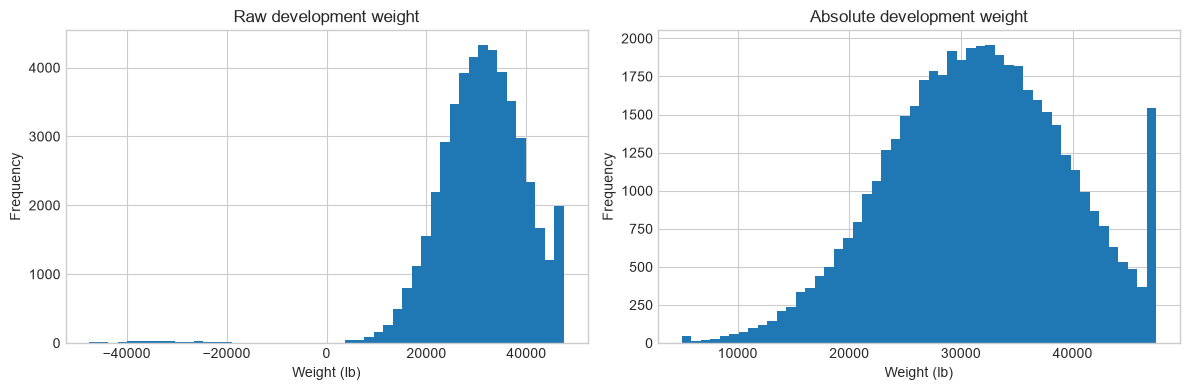

In [5]:
weight_quality = pd.DataFrame({
    "development": [train["weight"].isna().sum(), train["weight"].lt(0).sum(), train["weight"].abs().median()],
    "validation": [validation["weight"].isna().sum(), validation["weight"].lt(0).sum(), validation["weight"].abs().median()],
}, index=["missing", "negative", "median_absolute_weight"])
display(weight_quality)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train["weight"].plot.hist(bins=50, ax=axes[0], title="Raw development weight")
train["weight"].abs().plot.hist(bins=50, ax=axes[1], title="Absolute development weight")
for axis in axes:
    axis.set_xlabel("Weight (lb)")
plt.tight_layout()

## 3. Temporal structure

Because validation is entirely in the future, the primary model-selection protocol should be rolling or expanding-window validation rather than random cross-validation.

,development,validation
date,,
2025-01,4918,0
2025-02,4337,0
2025-03,5036,0
2025-04,4819,0
2025-05,4913,0
2025-06,4783,0
2025-07,4912,0
2025-08,4759,0
2025-09,4670,0


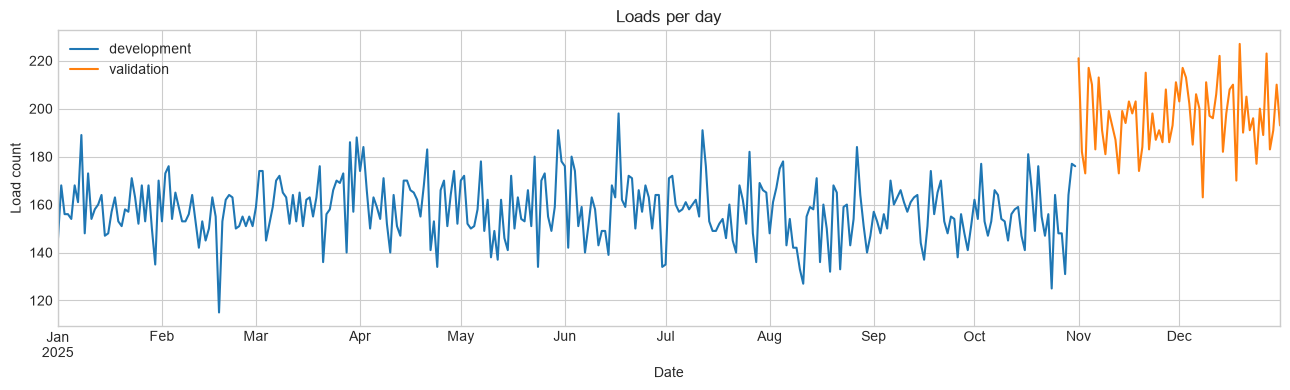

In [6]:
daily_counts = pd.concat([
    train.groupby("date").size().rename("development"),
    validation.groupby("date").size().rename("validation"),
], axis=1)

fig, axis = plt.subplots(figsize=(13, 4))
daily_counts.plot(ax=axis, linewidth=1.5)
axis.set(title="Loads per day", xlabel="Date", ylabel="Load count")
plt.tight_layout()

monthly_counts = pd.concat({
    "development": train.groupby(train["date"].dt.to_period("M")).size(),
    "validation": validation.groupby(validation["date"].dt.to_period("M")).size(),
}, axis=1).fillna(0).astype(int)
display(monthly_counts)

## 4. Target and rate-per-mile behavior

Rate per mile normalizes the target for trip length and is a candidate modeling target. Extreme values are inspected but not removed automatically; robust loss and sensitivity analysis will be evaluated later.

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
posted_rate,"48,000.0000","2,373.9807","1,486.4932",57.2200,327.1688,599.7385,"1,251.5550","2,030.7600","3,330.7500","4,953.7665","5,972.8340","25,533.0000"
rate_per_mile,"48,000.0000",2.2153,0.5839,0.3337,1.6735,1.8075,1.9870,2.1453,2.3427,2.7359,3.1769,14.1253


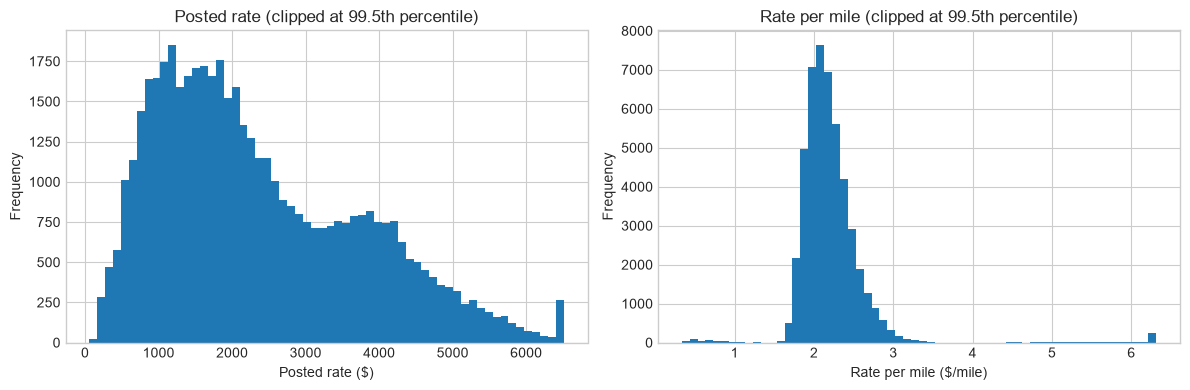

In [7]:
analysis = train.assign(
    rate_per_mile=train["posted_rate"] / train["distance"],
    month=train["date"].dt.to_period("M").astype(str),
)

target_summary = analysis[["posted_rate", "rate_per_mile"]].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
).T
display(target_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
analysis["posted_rate"].clip(upper=analysis["posted_rate"].quantile(0.995)).plot.hist(
    bins=60, ax=axes[0], title="Posted rate (clipped at 99.5th percentile)"
)
analysis["rate_per_mile"].clip(upper=analysis["rate_per_mile"].quantile(0.995)).plot.hist(
    bins=60, ax=axes[1], title="Rate per mile (clipped at 99.5th percentile)"
)
axes[0].set_xlabel("Posted rate ($)")
axes[1].set_xlabel("Rate per mile ($/mile)")
plt.tight_layout()

In [8]:
q1, q3 = analysis["rate_per_mile"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 3 * iqr, q3 + 3 * iqr
rpm_outliers = ~analysis["rate_per_mile"].between(lower_fence, upper_fence)

print(f"Conservative 3x-IQR RPM fences: {lower_fence:.3f} to {upper_fence:.3f}")
print(f"Rows outside fences: {rpm_outliers.sum():,} ({rpm_outliers.mean():.2%})")
display(analysis.loc[rpm_outliers].sort_values("rate_per_mile").head(10))
display(analysis.loc[rpm_outliers].nlargest(10, "rate_per_mile"))

Conservative 3x-IQR RPM fences: 0.920 to 3.410
Rows outside fences: 663 (1.38%)


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,rate_per_mile,month
14102,TR-014103,Buffalo,Bakersfield,41.6768,-78.5670,33.2883,-116.6793,"2,536.4000",Dry Van,"27,044.0000",2025-03-30,1.0339,1.7726,846.4200,0.3337,2025-03
25798,TR-025799,Albany,Reno,43.9697,-71.0584,39.5484,-118.6484,"2,894.3000",Dry Van,"32,383.0000",2025-06-12,1.3384,1.8800,969.8300,0.3351,2025-06
23043,TR-023044,Phoenix,Philadelphia,28.7567,-115.8773,39.2232,-72.9671,"2,983.4000",Dry Van,"37,692.0000",2025-05-26,1.1683,2.3169,"1,047.9100",0.3512,2025-05
46173,TR-046174,Philadelphia,El Paso,39.2232,-72.9671,33.3107,-110.3123,"2,490.9000",Dry Van,"22,411.0000",2025-10-20,0.8788,2.4055,880.1300,0.3533,2025-10
508,TR-000509,Las Vegas,Grand Rapids,33.2235,-115.2499,43.4380,-86.2917,"1,976.4000",Flatbed,"28,233.0000",2025-01-04,0.8631,1.8220,699.4100,0.3539,2025-01
2511,TR-002512,Buffalo,San Antonio,41.6768,-78.5670,29.5097,-98.4006,"1,644.3000",Flatbed,"22,022.0000",2025-01-16,0.9994,1.8731,596.0400,0.3625,2025-01
40600,TR-040601,Fort Wayne,Phoenix,41.3156,-85.3621,28.7567,-115.8773,"2,210.6000",Dry Van,"24,954.0000",2025-09-14,0.7828,1.7273,808.7400,0.3658,2025-09
22458,TR-022459,Salt Lake City,Mobile,35.0349,-113.1890,31.8044,-88.2519,"1,632.3000",Dry Van,"-32,048.0000",2025-05-22,1.4319,2.1075,599.7700,0.3674,2025-05
22464,TR-022465,Kansas City,Los Angeles,39.4110,-91.1245,28.5662,-116.7025,"1,909.1000",Dry Van,"32,899.0000",2025-05-22,1.4101,2.0978,709.4600,0.3716,2025-05
1555,TR-001556,El Paso,New York,33.3107,-110.3123,40.0067,-73.7984,"2,415.0000",Dry Van,"39,284.0000",2025-01-10,0.9709,1.8324,911.4400,0.3774,2025-01


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,rate_per_mile,month
22254,TR-022255,Greensboro,Cincinnati,35.9819,-82.7838,37.1571,-86.7750,314.7000,Reefer,"-36,485.0000",2025-05-21,1.3726,1.2422,"4,445.2300",14.1253,2025-05
36609,TR-036610,Chattanooga,Atlanta,35.2979,-87.1865,34.8493,-86.2894,98.4000,Reefer,"22,226.0000",2025-08-20,1.0347,2.5846,"1,386.4200",14.0896,2025-08
870,TR-000871,Tulsa,Baton Rouge,33.4589,-94.7856,30.5013,-92.6537,305.6000,Reefer,"26,447.0000",2025-01-06,0.8086,2.6418,"4,069.2400",13.3156,2025-01
17070,TR-017071,Toledo,Dayton,41.9766,-84.4590,39.8721,-85.6293,201.5000,Flatbed,"38,714.0000",2025-04-18,1.3028,1.4426,"2,609.3400",12.9496,2025-04
27969,TR-027970,Buffalo,Boston,41.6768,-78.5670,39.2746,-69.5000,589.9000,Reefer,"24,951.0000",2025-06-25,1.3392,2.5880,"7,597.5200",12.8793,2025-06
23369,TR-023370,Amarillo,Lubbock,33.1714,-104.3679,29.8753,-99.8546,412.4000,Flatbed,"35,494.0000",2025-05-28,1.3858,1.4058,"5,308.9600",12.8733,2025-05
28012,TR-028013,Montgomery,Houston,31.3760,-86.1074,30.7116,-94.7655,604.3000,Reefer,"39,690.0000",2025-06-25,1.3114,2.7611,"7,773.3700",12.8634,2025-06
45483,TR-045484,Greensboro,Columbia,35.9819,-82.7838,34.6357,-83.2851,153.8000,Dry Van,"34,198.0000",2025-10-15,1.0026,1.4639,"1,971.2100",12.8167,2025-10
1415,TR-001416,Montgomery,Birmingham,31.3760,-86.1074,33.4579,-86.7279,198.2000,Reefer,"25,383.0000",2025-01-09,0.9966,2.6645,"2,509.9600",12.6638,2025-01
21968,TR-021969,Jacksonville,Columbia,31.9869,-84.4890,34.6357,-83.2851,254.5000,Dry Van,"32,993.0000",2025-05-19,1.2128,1.5287,"3,220.6600",12.6549,2025-05


## 5. Categorical coverage and cold-start risk

Unseen cities or routes make pure route memorization unsuitable. Coordinates and generalized route features provide fallback information.

In [9]:
train_cities = set(train["pickup"]) | set(train["delivery"])
validation_cities = set(validation["pickup"]) | set(validation["delivery"])
new_cities = sorted(validation_cities - train_cities)

train_routes = set(zip(train["pickup"], train["delivery"]))
validation_route_pairs = list(zip(validation["pickup"], validation["delivery"]))
seen_route = pd.Series([route in train_routes for route in validation_route_pairs], index=validation.index)
involves_new_city = ~validation["pickup"].isin(train_cities) | ~validation["delivery"].isin(train_cities)

coverage = pd.Series({
    "development_cities": len(train_cities),
    "validation_cities": len(validation_cities),
    "new_validation_cities": len(new_cities),
    "validation_rows_with_seen_route_pct": seen_route.mean() * 100,
    "validation_rows_with_new_city_pct": involves_new_city.mean() * 100,
})
display(coverage.to_frame("value"))
print("New validation cities:", new_cities)

display(pd.crosstab(train["equipment"], columns="development", normalize=True).mul(100))
display(pd.crosstab(validation["equipment"], columns="validation", normalize=True).mul(100))

,value
development_cities,64.0000
validation_cities,72.0000
new_validation_cities,8.0000
validation_rows_with_seen_route_pct,87.8250
validation_rows_with_new_city_pct,12.0583


New validation cities: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']


col_0,development
equipment,
Dry Van,56.6708
Flatbed,18.2354
Reefer,25.0937


col_0,validation
equipment,
Dry Van,56.5000
Flatbed,18.0750
Reefer,25.4250


## 6. Train-to-validation numerical drift

Compare central tendency, spread, and quantiles. This is descriptive covariate drift analysis, not a substitute for temporal backtesting.

In [10]:
drift_columns = ["distance", "weight", "market_index", "quote_signal"]
drift_rows = []
for column in drift_columns:
    development_values = train[column].abs() if column == "weight" else train[column]
    validation_values = validation[column].abs() if column == "weight" else validation[column]
    drift_rows.append({
        "feature": column,
        "development_mean": development_values.mean(),
        "validation_mean": validation_values.mean(),
        "standardized_mean_shift": (validation_values.mean() - development_values.mean()) / development_values.std(),
        "development_p05": development_values.quantile(0.05),
        "validation_p05": validation_values.quantile(0.05),
        "development_p95": development_values.quantile(0.95),
        "validation_p95": validation_values.quantile(0.95),
    })
drift = pd.DataFrame(drift_rows).set_index("feature")
display(drift)

,development_mean,validation_mean,standardized_mean_shift,development_p05,validation_p05,development_p95,validation_p95
feature,,,,,,,
distance,"1,135.8567","1,141.7731",0.0081,236.1000,234.0900,"2,562.3000","2,592.9300"
weight,"31,417.2492","31,282.9546",-0.0168,"18,005.9500","18,003.8000","44,965.2000","44,689.6000"
market_index,1.0834,0.9269,-0.9309,0.8363,0.8145,1.3660,1.0409
quote_signal,2.0625,2.0513,-0.0382,1.6061,1.6917,2.5508,2.4137


## 7. Market and quote-signal stability

A feature can be highly predictive under random splitting but unstable over time. Monthly relationships between `quote_signal` and observed rate per mile are therefore examined explicitly.

,rows,corr_quote_to_rpm,quote_mean,quote_std,market_mean
month,,,,,
2025-01,4918,0.4467,2.0684,0.2503,0.9267
2025-02,4337,0.4790,2.0971,0.2517,0.9960
2025-03,5036,0.4858,2.1795,0.2729,1.0729
2025-04,4819,-0.4717,1.9634,0.2604,1.2076
2025-05,4913,-0.4592,1.9128,0.2658,1.3015
2025-06,4783,0.4766,2.2960,0.2889,1.2803
2025-07,4912,-0.4683,1.9230,0.2651,1.2009
2025-08,4759,-0.0136,2.0522,0.2227,0.9815
2025-09,4670,0.4814,2.1998,0.2799,0.8930


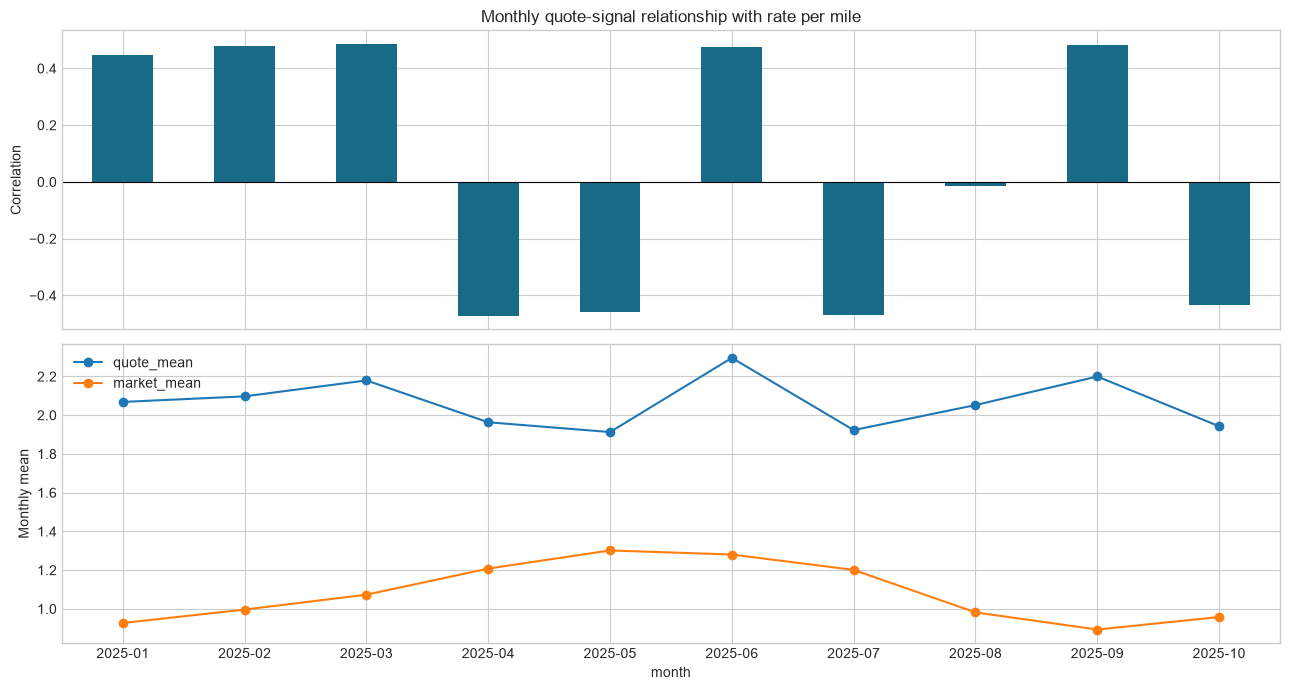

In [11]:
monthly_signal = []
for month, group in analysis.groupby("month", sort=True):
    monthly_signal.append({
        "month": month,
        "rows": len(group),
        "corr_quote_to_rpm": group["quote_signal"].corr(group["rate_per_mile"]),
        "quote_mean": group["quote_signal"].mean(),
        "quote_std": group["quote_signal"].std(),
        "market_mean": group["market_index"].mean(),
    })
monthly_signal = pd.DataFrame(monthly_signal).set_index("month")
display(monthly_signal)

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
monthly_signal["corr_quote_to_rpm"].plot.bar(ax=axes[0], color="#176B87")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("Correlation")
axes[0].set_title("Monthly quote-signal relationship with rate per mile")
monthly_signal[["quote_mean", "market_mean"]].plot(ax=axes[1], marker="o")
axes[1].set_ylabel("Monthly mean")
plt.tight_layout()

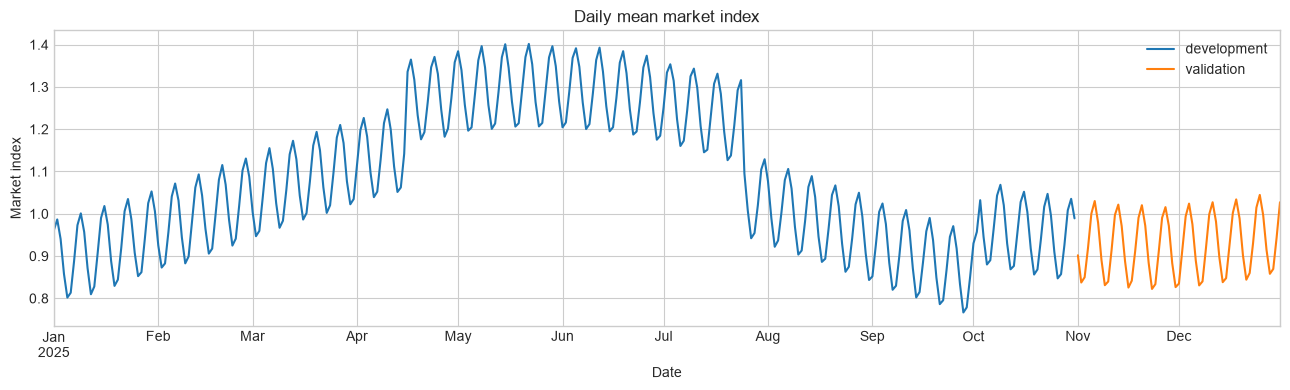

In [12]:
daily_market = pd.concat([
    train.groupby("date")["market_index"].mean().rename("development"),
    validation.groupby("date")["market_index"].mean().rename("validation"),
], axis=1)

fig, axis = plt.subplots(figsize=(13, 4))
daily_market.plot(ax=axis, linewidth=1.5)
axis.set(title="Daily mean market index", xlabel="Date", ylabel="Market index")
plt.tight_layout()

## 8. Shared preprocessing smoke test

Fit the reusable preprocessing stage on development features only, then transform both datasets. This confirms stable schemas, fold-local imputations, unseen-category compatibility, and finite model inputs.

In [13]:
X_development, y = split_features_target(train)
preprocessing = build_preprocessing_pipeline()
X_development_prepared = preprocessing.fit_transform(X_development)
X_validation_prepared = preprocessing.transform(validation)

assert list(X_development_prepared.columns) == list(X_validation_prepared.columns)
assert not X_development_prepared.isna().any().any()
assert not X_validation_prepared.isna().any().any()
assert (X_development_prepared["weight"] >= 0).all()
assert (X_validation_prepared["weight"] >= 0).all()

print(f"Prepared development shape: {X_development_prepared.shape}")
print(f"Prepared validation shape:  {X_validation_prepared.shape}")
display(X_development_prepared.head())

Prepared development shape: (48000, 32)
Prepared validation shape:  (12000, 32)


,pickup,delivery,equipment,route,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,log_distance,weight,weight_missing,weight_was_negative,market_index,market_index_missing,quote_signal,quote_signal_missing,latitude_delta,longitude_delta,haversine_miles,bearing_sin,bearing_cos,days_since_reference,month,quarter,day_of_week,day_of_year,is_weekend,day_of_week_sin,day_of_week_cos,day_of_year_sin,day_of_year_cos
0,Richmond,Baltimore,Dry Van,Richmond -> Baltimore,38.0912,-76.7891,38.1691,-72.7456,274.3000,5.6179,"30,658.0000",0,0,0.9568,0,2.3960,0,0.0779,4.0434,219.8066,0.9989,0.0462,0.0000,1,1,2,1,0,0.9749,-0.2225,0.0172,0.9999
1,Richmond,Philadelphia,Reefer,Richmond -> Philadelphia,38.0912,-76.7891,39.2232,-72.9671,280.5000,5.6401,"17,555.0000",0,0,0.9762,0,2.4335,0,1.1320,3.8220,220.5235,0.9275,0.3739,0.0000,1,1,2,1,0,0.9749,-0.2225,0.0172,0.9999
2,Philadelphia,Green Bay,Dry Van,Philadelphia -> Green Bay,39.2232,-72.9671,44.3030,-87.5287,967.8000,6.8761,"31,721.0000",0,0,1.0097,0,1.8449,0,5.0798,-14.5616,826.9118,-0.8677,0.4971,0.0000,1,1,2,1,0,0.9749,-0.2225,0.0172,0.9999
3,Hartford,Atlanta,Dry Van,Hartford -> Atlanta,39.5533,-72.1805,34.8493,-86.2894,965.4000,6.8736,"32,333.0000",0,0,0.9452,0,1.8771,0,-4.7039,-14.1089,840.5325,-0.9493,-0.3143,0.0000,1,1,2,1,0,0.9749,-0.2225,0.0172,0.9999
4,Dallas,Nashville,Reefer,Dallas -> Nashville,31.8302,-94.3834,35.2948,-88.0892,541.9000,6.2969,"35,183.0000",0,0,0.9848,0,2.5630,0,3.4645,6.2943,434.1589,0.8176,0.5758,0.0000,1,1,2,1,0,0.9749,-0.2225,0.0172,0.9999


## Findings to carry into modeling

1. Use expanding-window temporal validation; random splitting would not represent the November–December prediction period.
2. Compare direct-rate and rate-per-mile targets under MAE, RMSE, median absolute error, and WAPE.
3. Treat negative weights as sign corruption, retain anomaly indicators, and learn imputations inside each training fold.
4. Use robust objectives or sensitivity analysis for target outliers instead of deleting them without evidence.
5. Measure `quote_signal` by month and perform an explicit include/exclude ablation because its relationship may be temporally unstable.
6. Include geographic and distance features so unseen cities and routes do not rely solely on categorical memorization.
7. Keep `load_id` out of the model because it is an identifier and encodes row chronology.
8. Fit every learned preprocessing statistic within each temporal fold to prevent leakage.